# Machine Learning Metrics. Bagging and Random Forest. Introduction to Adaboost.

## Cross Validation

### Why Do We Use Cross-Validation?

The main goal of cross-validation is to answer a simple question:

> **How well is our model likely to perform on new, unseen data?**

A model can perform very well on the data used for training simply because it has learned patterns that are specific to that dataset. What we really care about, however, is whether the model can make good predictions for observations it has **not seen before**.

A single train-test split gives us only one answer to this question. The result can depend on which observations happened to end up in the training and test sets. For example, one split might contain relatively easy observations in the test set, while another split might contain more difficult ones.

Cross-validation reduces this dependence by repeating the evaluation several times. Each observation is used for validation and training in different iterations:

```text
Dataset
   │
   ├── Fold 1 → validation
   │   Folds 2–K → training
   │
   ├── Fold 2 → validation
   │   Folds 1, 3–K → training
   │
   ├── ...
   │
   └── Fold K → validation
       Folds 1–(K-1) → training
```

We then combine the results from all folds.

This gives us a more reliable estimate of how the model is likely to perform on unseen data.

Cross-validation is therefore useful for three main reasons:

1. **Estimating generalization performance.**
   It evaluates the model on observations that were not used to train it.

2. **Using the available data efficiently.**
   Instead of permanently setting aside a large part of a small dataset as a single validation set, different parts of the data are used for validation in different iterations.

3. **Comparing models and hyperparameters.**
   The same cross-validation procedure can be used to compare candidate models or hyperparameter values. The essential condition is that **all candidates are evaluated on exactly the same folds**. Then the difficulty of each fold affects every candidate equally, and the per-fold differences are meaningful.

For example, suppose we compare two models on the same 5 folds:

| Model       | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 |      Mean |
| ----------- | -----: | -----: | -----: | -----: | -----: | --------: |
| Model A     |   0.84 |   0.87 |   0.82 |   0.85 |   0.86 | **0.848** |
| Model B     |   0.88 |   0.79 |   0.83 |   0.81 |   0.85 | **0.832** |
| Difference (A − B) | -0.04 | +0.08 | -0.01 | +0.04 | +0.01 | **+0.016** |

Model A has the higher mean and wins in 3 of 5 folds. But look at the last row: the difference between the models changes a lot from fold to fold(from −0.04 to +0.08), while its average is only +0.016. The difference is smaller than its own variation, so the evidence that A is better is weak.

Trust a difference between two models only if it is clearly larger than its variation across folds.


The key concept is:

> **Cross-validation does not make the model better. It gives us a more reliable way to evaluate and compare models using the data we already have.**

It is especially useful when the dataset is not large enough to comfortably reserve a separate validation set for every model-development decision.

### K-Fold Cross-Validation

A simple approach is to split the dataset into training and test sets. However, the result can depend strongly on the particular split we happened to choose.

**K-Fold Cross-Validation** reduces this problem by evaluating the model on several different parts of the dataset.

## The Basic Idea

Suppose we have a dataset and choose:

$$
K=5
$$

We divide the data into five approximately equal parts, called **folds**.

Then we repeat the following process five times:

1. Use four folds to train the model.
2. Use the remaining fold to evaluate the model.
3. Record the validation score.
4. Change the validation fold and repeat.

For example:

| Iteration | Training        | Validation |
| --------- | --------------- | ---------- |
| 1         | Fold 2, 3, 4, 5 | Fold 1     |
| 2         | Fold 1, 3, 4, 5 | Fold 2     |
| 3         | Fold 1, 2, 4, 5 | Fold 3     |
| 4         | Fold 1, 2, 3, 5 | Fold 4     |
| 5         | Fold 1, 2, 3, 4 | Fold 5     |

Each observation is therefore used for validation exactly once.

Finally, we average the five validation scores:

$$
\widehat{R}_{CV}
=
\frac{1}{K}
\sum_{k=1}^{K} e_k
$$

where $e_k$ is the validation error from fold $k$.

### The intuition

Instead of asking:

> "How well does my model perform on this particular validation split?"

we ask:

> "How well does my model perform on several different validation splits?"

This usually gives us a more reliable estimate of model performance.

### Example

Suppose we have 8 observations and use 4-fold cross-validation.

The folds could be:

| Fold  | Validation | Training         |
| ----- | ---------- | ---------------- |
| $F_1$ | 1, 2       | 3, 4, 5, 6, 7, 8 |
| $F_2$ | 3, 4       | 1, 2, 5, 6, 7, 8 |
| $F_3$ | 5, 6       | 1, 2, 3, 4, 7, 8 |
| $F_4$ | 7, 8       | 1, 2, 3, 4, 5, 6 |

Suppose the model produces these average validation errors:

$$
e_1=0.40
$$

$$
e_2=0.30
$$

$$
e_3=0.40
$$

$$
e_4=0.30
$$

The final cross-validation error is:

$$
\widehat{R}_{CV}
=
\frac{0.40+0.30+0.40+0.30}{4}
=
0.35
$$

The important point is not the formula itself, but the procedure:

**split → train → validate → repeat → average.**

---

### How Many Folds Should We Use?

Common choices are:

$$
K=5
$$

or

$$
K=10
$$

There is a trade-off.

With a small $K$, each model is trained on fewer observations.

With a large $K$, each model is trained on more observations, but we have to train the model more times.


In practice, **5-fold and 10-fold cross-validation are common choices** because they provide a good balance between computational cost and the quality of the estimate.

### Important Variants of Cross-Validation

Not every dataset should be split in exactly the same way.

### Stratified K-Fold

For classification, especially with imbalanced classes, we often use **Stratified K-Fold**.

Suppose our dataset contains:

* 90% class 0;
* 10% class 1.

We want each fold to have approximately the same class proportions.

For example:

| Dataset      | Class 0 | Class 1 |
| ------------ | ------: | ------: |
| Full dataset |     90% |     10% |
| Fold 1       |    ≈90% |    ≈10% |
| Fold 2       |    ≈90% |    ≈10% |
| Fold 3       |    ≈90% |    ≈10% |
| ...          |     ... |     ... |

This prevents a fold from accidentally containing too few examples of the minority class.

For classification, **Stratified K-Fold is often a good default**.

---
p-Based Cross-Validation

Sometimes several observations belong to the same group.

For example:

* several measurements from one patient;
* several transactions from one customer;
* several images of one person;
* several documents written by one author.

We should not put some observations from the same group into training and others into validation.

Otherwise, the model may learn information specific to that group and produce an overly optimistic result.

The rule is:

> **All observations from the same group should stay in the same fold.**

---

### Time-Series Cross-Validation

For time-dependent data, ordinary random K-Fold is usually inappropriate.

We should never train on future data and then evaluate on the past.

Instead, we preserve the temporal order:

```text
Train:      2020
Validate:   2021

Train:      2020, 2021
Validate:   2022

Train:      2020, 2021, 2022
Validate:   2023
```

The idea is to reproduce the real situation:

> **Use the past to predict the future.**

---

### Cross-Validation for Model Selection

Cross-validation is also useful for choosing between models or hyperparameters.

Suppose we want to choose the regularization parameter:

$$
C \in \{0.01, 0.1, 1, 10\}
$$

We can run cross-validation for each value:

|  $C$ | CV Error |
| ---: | -------: |
| 0.01 |     0.42 |
|  0.1 |     0.31 |
|    1 |     0.25 |
|   10 |     0.28 |

We would choose:

$$
C=1
$$

because it produces the lowest cross-validation error.

The general idea is:

$$
\hat{\lambda}
=
\arg\min_{\lambda}
\widehat{R}_{CV}(\lambda)
$$

In simple terms:

> **Try different settings, use cross-validation to compare them, and choose the one that performs best on average.**

---

### Why We Still Need a Test Set

There is an important subtlety when using cross-validation for model selection.

Suppose we try 100 different models and choose the one with the best CV score.

That score was used to **select the model**, so it can be somewhat optimistic.

Therefore, if we want a final unbiased estimate of performance, we should use either:

1. a separate test set that was not used during model development; or
2. nested cross-validation.

A useful workflow is:

```text
Training data
     ↓
Cross-validation
     ↓
Choose model / hyperparameters
     ↓
Train final model
     ↓
Independent test set
     ↓
Final performance
```

The test set should be used **only for the final evaluation**.

---

### Nested Cross-Validation: how the data are split

Nested CV uses **two levels of splitting**. The outer split sets aside a test part. The inner split divides what remains, to choose hyperparameters.

#### Step 1. Outer split (5 folds)

The dataset (100 samples) is divided into 5 folds of 20 samples. Each fold takes one turn as the **test set**; the other 4 folds form the **training set**.

```text
            fold 1   fold 2   fold 3   fold 4   fold 5
Outer 1:    [TEST ]  [train]  [train]  [train]  [train]
Outer 2:    [train]  [TEST ]  [train]  [train]  [train]
Outer 3:    [train]  [train]  [TEST ]  [train]  [train]
Outer 4:    [train]  [train]  [train]  [TEST ]  [train]
Outer 5:    [train]  [train]  [train]  [train]  [TEST ]
```

#### Step 2. Inner split (inside the outer training set only)

Take **Outer 1**. Its 80 training samples are divided again, into 3 inner folds (A, B, C). The test fold (20 samples) is **not involved** here.

```text
Outer 1:   [ TEST: 20 samples ]   [ outer training set: 80 samples ]
                                   [  A  ] [  B  ] [  C  ]   <- inner folds
```

For **each** hyperparameter configuration, three rounds are run:

```text
Round 1:   fit on A + B     validate on C
Round 2:   fit on A + C     validate on B
Round 3:   fit on B + C     validate on A
```

The three validation scores are averaged, giving one number per configuration. The configuration with the best average is selected.

#### Step 3. Evaluation

```text
1. Retrain the model on all 80 outer-training samples with the selected configuration.
2. Score it on the 20 TEST samples.  ->  one number (outer score)
```

#### Step 4. Repeat

Steps 2-3 are repeated for Outer 2, 3, 4, 5. Each outer iteration builds **its own inner folds** from its own training set. At the end there are 5 outer scores; their mean is the final estimate.

#### Key rule

```text
TEST fold  : used once, only for the final score. Never for choosing hyperparameters.
Inner folds: used only for choosing hyperparameters.
```
---

### Data Leakage

One of the most important rules in cross-validation is:

> **Validation data must not influence the training process.**

Data leakage happens when information from the validation or test data accidentally enters the training process.

Common examples include:

* scaling the entire dataset before cross-validation;
* selecting features using the entire dataset;
* imputing missing values using statistics from the entire dataset;
* using target information from the validation data;
* putting related observations in both training and validation.

### Example

This can cause leakage:

```python
X_scaled = scaler.fit_transform(X)

cross_validate(model, X_scaled, y, cv=5)
```

The scaler was fitted using the entire dataset, including the future validation folds.

Instead, use a `Pipeline`:

```python
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])
```

Now, during each CV iteration, the scaler is fitted **only on the training fold**.

This principle also applies to:

* imputation;
* feature selection;
* dimensionality reduction;
* encoding;
* other data-dependent preprocessing steps.

### Example: K-Fold Cross-Validation in Python




In [ ]:
from sklearn.datasets import make_regression
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_validate

X, y = make_regression(
    n_samples=200,
    n_features=8,
    noise=10.0,
    random_state=0
)

model = Ridge(alpha=1.0)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

results = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring="neg_mean_squared_error"
)

mse = -results["test_score"].mean()

print(f"Cross-validated MSE: {mse:.3f}")

Cross-validated MSE: 118.220


### Example: Stratified Cross-Validation






In [ ]:
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

X, y = make_classification(
    n_samples=400,
    n_features=10,
    weights=[0.85, 0.15],
    random_state=0
)

model = RandomForestClassifier(
    n_estimators=200,
    random_state=0
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

results = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring=["accuracy", "balanced_accuracy", "f1", "roc_auc"]
)

print("Accuracy:", results["test_accuracy"].mean())
print("Balanced accuracy:",
      results["test_balanced_accuracy"].mean())
print("F1:", results["test_f1"].mean())
print("ROC AUC:", results["test_roc_auc"].mean())

Accuracy: 0.9475
Balanced accuracy: 0.8487933634992458
F1: 0.8028571428571428
ROC AUC: 0.9349688210531054


### Common Mistakes

### Mistake 1: Using the test set to choose the model

The test set should be reserved for the final evaluation.

### Mistake 2: Preprocessing before cross-validation

Scaling, imputation, feature selection, and similar operations should be performed **inside the CV process**, usually with a `Pipeline`.

### Mistake 3: Using ordinary K-Fold for dependent data

Use an appropriate strategy for:

* grouped data;
* time series;
* other structured observations.

### Mistake 4: Reporting the best CV score after trying many models

If the same CV results were used to select the model, the reported score can be optimistic.

Use an independent test set or nested CV for final evaluation.

### Mistake 5: Using an inappropriate metric

The evaluation metric should match the problem. For example, accuracy may be misleading for highly imbalanced classification.


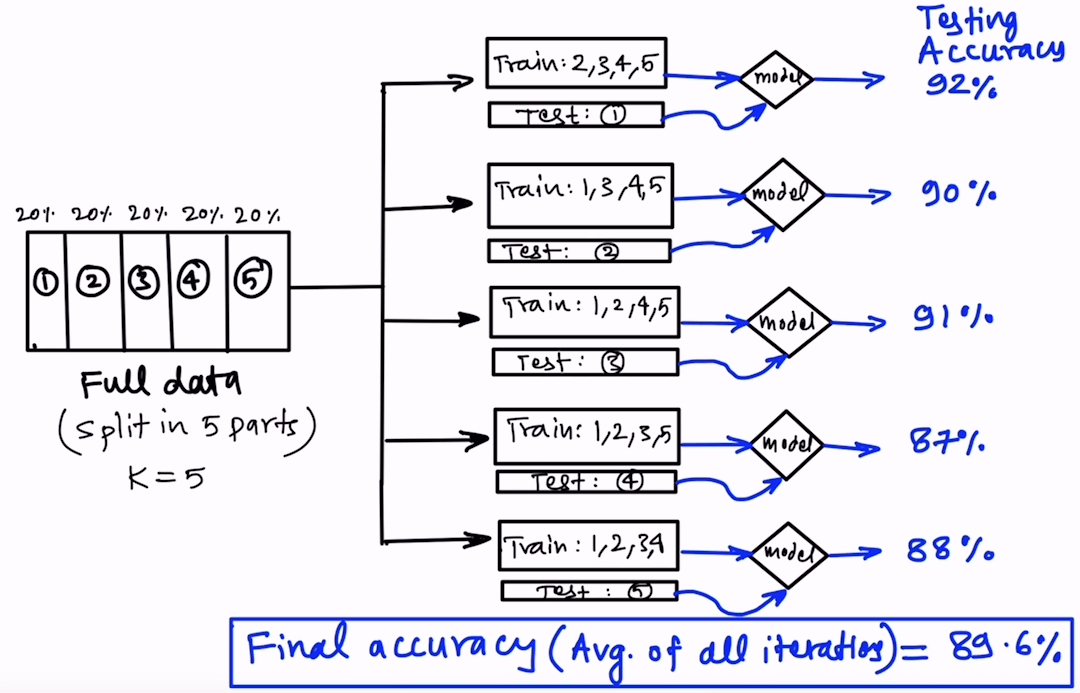

## Bootstrap

**Bootstrap** is a resampling technique used mainly to estimate the **uncertainty and variability of a statistic or model estimate**.

The key idea is simple: suppose we have only one dataset, but we want to understand how much our result might change if we had collected a slightly different sample from the same population.

Since collecting many new datasets is usually impossible, we create many **bootstrap samples** from the dataset we already have. Each bootstrap sample has the same size as the original dataset, but observations are selected **with replacement**, meaning that the same observation can appear several times while some observations may not appear at all.

For example, if our original dataset is `A B C D E`, one bootstrap sample could be `A C C D E`, another could be `B B C D A`, and another could be `E A A C D`.

We calculate the statistic of interest for every bootstrap sample. For example, if we are interested in the mean, one bootstrap sample might give a mean of 12.8, another 13.4, and another 12.5. After repeating this process many times, we have a distribution of estimates rather than a single estimate. If these estimates are close together, our result is relatively stable; if they are widely spread out, there is greater uncertainty.

Conceptually, the process is: **original dataset → many bootstrap samples → many estimates → distribution of estimates → estimate of uncertainty**. If the original estimate is $\hat{\theta}$, the bootstrap procedure produces many estimates $\hat{\theta}^{(1)}, \hat{\theta}^{(2)}, \ldots, \hat{\theta}^{(B)}$, where $B$ is the number of bootstrap samples, often 1,000 or more. This distribution can then be used to estimate quantities such as standard errors, confidence intervals, or the variability of model parameters and evaluation metrics. Bootstrap is related to cross-validation because both repeatedly reuse the available data, but their main purposes are different: **cross-validation is primarily used to estimate predictive performance, while bootstrap is primarily used to understand the uncertainty of an estimate**.





Suppose we train a classification model and evaluate it on a test set. We obtain:

$$
ROC\ AUC = 0.91
$$

But how reliable is this number?

The value $0.91$ depends on the particular test set we happened to use. If we had evaluated the model on another similar sample, the AUC might have been slightly different.

Bootstrap allows us to investigate this variability.

We repeatedly sample observations from the test set with replacement. For each bootstrap sample, we calculate the model's ROC AUC.

Conceptually:

Test set

   ↓

Bootstrap sample 1 → ROC AUC = 0.90

Bootstrap sample 2 → ROC AUC = 0.93

Bootstrap sample 3 → ROC AUC = 0.89
        ...

Bootstrap sample 1000 → ROC AUC = 0.92
   
   ↓

Distribution of ROC AUC

The resulting distribution shows how much the estimated model performance can vary across different samples.

For example, we might obtain:

$$
\text{ROC AUC}=0.91
$$

with an approximate 95% bootstrap interval:

$$
[0.88,;0.94]
$$

This tells us that the estimated performance is around 0.91, but there is some uncertainty around this value.

A narrow interval indicates that the estimated performance is relatively stable. A wide interval indicates greater uncertainty.

Original ROC AUC: 0.986
Mean bootstrap AUC: 0.986
Approximate 95% interval: [0.973, 0.996]


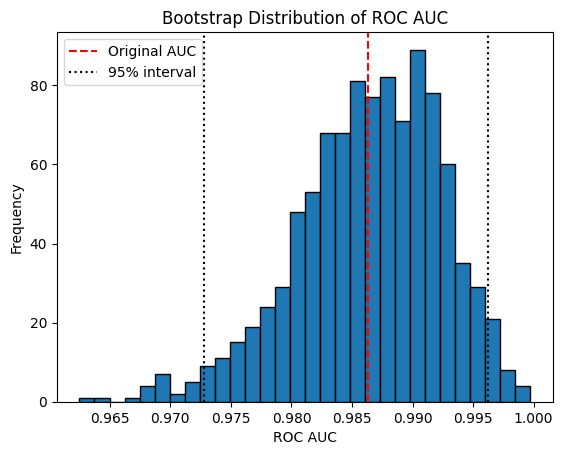

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score


X, y = make_classification( n_samples=1000, n_features=10, n_informative=5,
                           n_redundant=2, random_state=0 )

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                    stratify=y, random_state=0)

model = RandomForestClassifier(n_estimators=200, random_state=0)

model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:, 1]

original_auc = roc_auc_score(y_test, y_prob)
print(f"Original ROC AUC: {original_auc:.3f}")

n_bootstrap = 1000
bootstrap_auc = []
rng = np.random.default_rng(0)

for _ in range(n_bootstrap):
  indices = rng.choice(len(X_test), size=len(X_test), replace=True)
  y_bootstrap = y_test[indices]
  prob_bootstrap = y_prob[indices]
  if len(np.unique(y_bootstrap)) < 2:
      continue
  auc = roc_auc_score( y_bootstrap, prob_bootstrap )
  bootstrap_auc.append(auc)

bootstrap_auc = np.array(bootstrap_auc)
mean_auc = bootstrap_auc.mean()
lower = np.percentile( bootstrap_auc, 2.5)
upper = np.percentile( bootstrap_auc, 97.5)

print(f"Mean bootstrap AUC: {mean_auc:.3f}")
print(f"Approximate 95% interval: [{lower:.3f}, {upper:.3f}]")
plt.hist( bootstrap_auc, bins=30, edgecolor="black" )
plt.axvline( original_auc, color="red", linestyle="--", label="Original AUC" )
plt.axvline( lower, color="black", linestyle=":", label="95% interval" )
plt.axvline( upper, color="black", linestyle=":" )
plt.xlabel("ROC AUC")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of ROC AUC")
plt.legend()
plt.show()

**Bootstrap interval tells us about the uncertainty of our estimate of that performance!**

## Metrics

### 1. Confusion Matrix for Binary Classification

For binary classification, we compare the model's predictions with the true class labels.

A **confusion matrix** summarizes four possible outcomes:

|                        |     Actual Positive |     Actual Negative |
| ---------------------- | ------------------: | ------------------: |
| **Predicted Positive** |  True Positive (TP) | False Positive (FP) |
| **Predicted Negative** | False Negative (FN) |  True Negative (TN) |

* **True Positive (TP):** the model predicts positive, and the observation is actually positive.
* **True Negative (TN):** the model predicts negative, and the observation is actually negative.
* **False Positive (FP):** the model predicts positive, but the observation is actually negative.
* **False Negative (FN):** the model predicts negative, but the observation is actually positive.

Most classification metrics are calculated from these four numbers.

For example, in medical diagnosis, a **false positive** means that a healthy person is classified as having the disease, while a **false negative** means that a person with the disease is classified as healthy.


### 2. Confusion Matrix for Multiclass Classification

The same idea can be extended to **multiclass classification**, where the target has more than two possible classes.

For example, suppose a model classifies images into three classes:

* Cat
* Dog
* Horse

The confusion matrix could look like this:

|                     | Actual Cat | Actual Dog | Actual Horse |
| ------------------- | ---------: | ---------: | -----------: |
| **Predicted Cat**   |         45 |          5 |            2 |
| **Predicted Dog**   |          3 |         40 |            4 |
| **Predicted Horse** |          2 |          5 |           44 |

The **rows represent the model's predictions**, while the **columns represent the true classes**.

The diagonal contains the correct predictions:


In multiclass classification, each class can also be considered separately. For example, when evaluating the **Cat** class, we can treat "Cat" as the positive class and all other classes as negative:

```text
                  Cat          Not Cat
Predicted Cat      TP           FP
Predicted Not Cat  FN           TN
```

This allows us to calculate precision, recall, and other metrics **for each class separately**.

### 3. Accuracy

**Accuracy** is the proportion of all predictions that the model classified correctly.

$$
Accuracy =
\frac{TP + TN}
{TP + TN + FP + FN}
$$

In other words:

> **What proportion of all predictions were correct?**

For example, if a model makes 100 predictions and gets 92 of them correct, its accuracy is:

$$
Accuracy = \frac{92}{100} = 0.92
$$

Accuracy is easy to understand, but it can be misleading when the classes are highly imbalanced.

For example, if 95% of observations belong to the negative class, a model that always predicts "negative" achieves 95% accuracy while completely failing to detect the positive class.

Therefore, accuracy should not be used alone for strongly imbalanced classification problems.

### 4. Precision

**Precision** measures how often a positive prediction is actually correct.

$$
Precision =
\frac{TP}{TP + FP}
$$

In other words:

> **When the model predicts positive, how often is it right?**

For example, suppose a model identifies 100 observations as positive, but only 80 of them are actually positive.

Then:

$$
Precision = \frac{80}{100} = 0.80
$$

High precision means that the model produces relatively few **false positives**.

Precision is especially important when false positive predictions are costly. For example, if a system flags transactions as fraudulent, high precision means that most transactions flagged as fraud are actually fraudulent.

### 5. Recall (Sensitivity)

**Recall**, also called **sensitivity** or **true positive rate (TPR)**, measures how many of the actual positive observations the model successfully detects.

$$
Recall = Sensitivity =
\frac{TP}{TP + FN}
$$

In other words:

> **Of all observations that are actually positive, how many did the model find?**

For example, suppose 100 patients actually have a disease and the model correctly identifies 90 of them.

Then:

$$
Recall = \frac{90}{100} = 0.90
$$

High recall means that the model produces relatively few **false negatives**.

Recall is especially important when missing a positive case is costly. For example, in medical screening, we usually want to minimize the number of patients who have a disease but are incorrectly classified as healthy.

**Recall and sensitivity are the same metric.** The term "sensitivity" is particularly common in medical and diagnostic applications.


### 6. Specificity

**Specificity**, also called the **true negative rate (TNR)**, measures how many of the actual negative observations the model correctly identifies.

$$
Specificity =
\frac{TN}{TN + FP}
$$

In other words:

> **Of all observations that are actually negative, how many did the model correctly identify as negative?**

High specificity means that the model produces relatively few **false positives**.

For example, if 100 people are actually healthy and the model correctly classifies 95 of them as healthy:

$$
Specificity = \frac{95}{100} = 0.95
$$

Recall and specificity focus on opposite classes:

* **Recall / Sensitivity:** How well do we detect positives?
* **Specificity:** How well do we detect negatives?


### 7. F1 Score

**F1 score** combines precision and recall into a single metric. It is the harmonic mean of the two:

$$
F1 =
2 \cdot
\frac{Precision \cdot Recall}
{Precision + Recall}
$$

F1 is high only when **both precision and recall are high**.

For example, if:

$$
Precision = 0.80
$$

and

$$
Recall = 0.60
$$

then:

$$
F1 =
2 \cdot
\frac{0.80 \times 0.60}
{0.80 + 0.60}
\approx 0.69
$$

This is useful when we care about both types of errors involving the positive class.

The harmonic mean also makes F1 sensitive to very low values. A model cannot achieve a high F1 score by having excellent precision but very poor recall, or vice versa.


### 8. ROC Curve

Many classification models do not directly produce a class label. Instead, they produce a **score or probability** indicating how likely an observation is to belong to the positive class.

For example:

```text
Model score:

0.95 → very likely positive
0.80 → likely positive
0.55 → somewhat likely positive
0.20 → likely negative
0.05 → very likely negative
```

To convert these scores into class predictions, we choose a **threshold**.

For example, with a threshold of 0.5:

$$
p \geq 0.5 \rightarrow Positive
$$

$$
p < 0.5 \rightarrow Negative
$$

Changing the threshold changes the number of false positives and false negatives.

**ROC curve** (Receiver Operating Characteristic). It is a curve that shows the trade-off between the True Positive Rate and False Positive Rate at different classification thresholds.

It plots:

$$
TPR = \frac{TP}{TP+FN}
$$

against

$$
FPR = \frac{FP}{FP+TN}
$$

where:

$$
FPR = 1 - Specificity
$$

A model with a good ROC curve achieves high true positive rates while keeping the false positive rate relatively low.


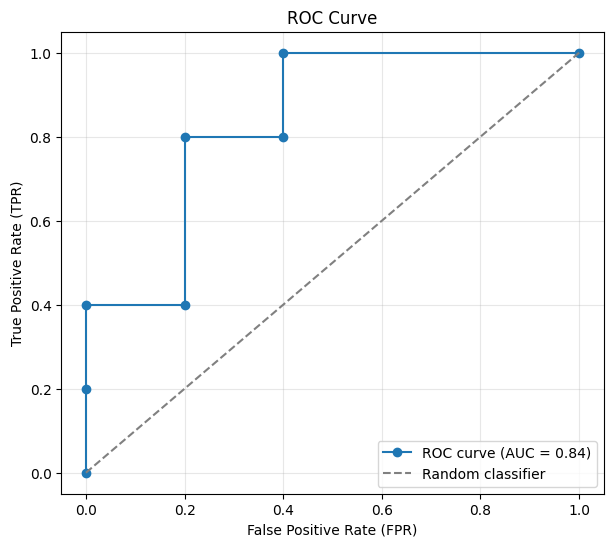

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

y_true = np.array([
    1, 1, 1, 1, 1,
    0, 0, 0, 0, 0
])
y_score = np.array([
    0.95, 0.85, 0.75, 0.60, 0.40,
    0.80, 0.55, 0.30, 0.20, 0.10
])
fpr, tpr, thresholds = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 6))
plt.plot(
    fpr,
    tpr,
    marker="o",
    label=f"ROC curve (AUC = {roc_auc:.2f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

```python
thresholds = [inf, 0.95, 0.85, 0.80, 0.75, 0.60, 0.55, 0.40, 0.30, 0.20, 0.10]
fpr        = [0.0, 0.0,  0.0,  0.2,  0.2,  0.2,  0.4,  0.4,  0.6,  0.8,  1.0]
tpr        = [0.0, 0.2,  0.4,  0.4,  0.6,  0.8,  0.8,  1.0,  1.0,  1.0,  1.0]
```

Each point on the ROC curve corresponds to a **different classification threshold**.

For example, with a high threshold, the model predicts positive only when it is very confident. This usually results in:

* fewer false positives;
* but also more false negatives.

As the threshold is lowered, more observations are classified as positive. This usually causes:

* **TPR to increase** because we detect more positive observations;
* **FPR to increase** because we also classify more negative observations as positive.

Therefore, moving along the ROC curve represents the trade-off between detecting positive observations and generating false positives.

The ideal point is near the **top-left corner**:

$$
FPR = 0,\qquad TPR = 1
$$

which corresponds to perfect classification.

The dashed diagonal represents a classifier with no ability to distinguish between the two classes. Its performance is equivalent to random guessing:

$$
TPR \approx FPR
$$

### 9. ROC AUC

ROC AUC is calculated from the **ROC curve**.

The ROC curve is created by evaluating the model at many different classification thresholds.

Suppose the model produces the following scores:

| Observation | True Class | Model Score |
| ----------- | ---------- | ----------: |
| A           | Positive   |        0.95 |
| B           | Positive   |        0.80 |
| C           | Positive   |        0.70 |
| D           | Negative   |        0.60 |
| E           | Negative   |        0.40 |
| F           | Negative   |        0.20 |

We can choose different thresholds, for example:

$$
0.95,\quad 0.80,\quad 0.70,\quad 0.60,\quad 0.40,\quad 0.20
$$

For each threshold, the model converts the scores into positive or negative predictions. We then calculate:

$$
TPR = \frac{TP}{TP+FN}
$$

and

$$
FPR = \frac{FP}{FP+TN}
$$

Each threshold therefore gives us one point:

$$
(FPR,\;TPR)
$$

Connecting these points produces the **ROC curve**.

The **AUC (Area Under the Curve)** is the area underneath this ROC curve:

$$
AUC = \int_0^1 TPR(FPR)\,dFPR
$$

In practice, we usually have a finite number of ROC points, so the area is approximated numerically, commonly using the trapezoidal rule.

The important intuition is:

> **AUC summarizes the performance of the model across all possible classification thresholds using a single number.**

There is also a useful probabilistic interpretation:

$$
AUC =
P(\text{a randomly chosen positive receives a higher score than a randomly chosen negative})
$$

For example, if:

$$
AUC = 0.90
$$

then, approximately, if we randomly select one positive and one negative observation, the model will assign a higher score to the positive observation **90% of the time**.

Therefore, AUC measures the model's ability to **rank positive observations above negative observations**, rather than its performance at one particular classification threshold.

A useful interpretation of the extreme cases is:

$$
AUC = 1.0
$$

means perfect ranking, while

$$
AUC = 0.5
$$

means that the model's ranking is no better than random.


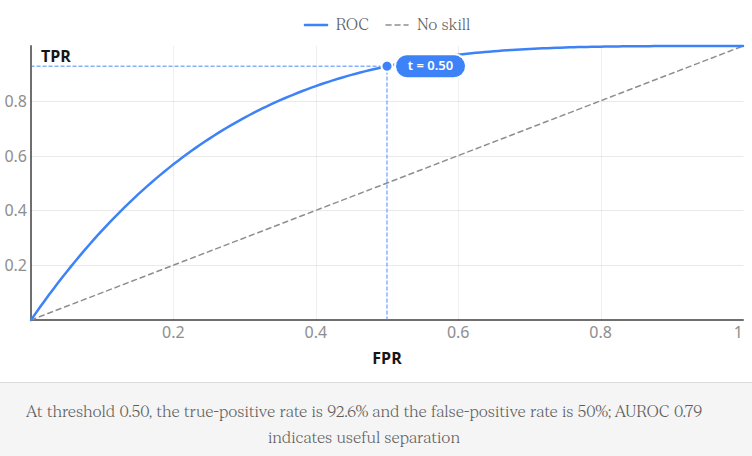

**In multiclass classification, ROC AUC is usually calculated by treating each class as "positive" against all other classes and then averaging the resulting AUC values.**

### 10. G-Mean

For imbalanced classification, we often want a model to perform well on **both classes**, rather than simply perform well on the majority class.

The **geometric mean (G-mean)** combines sensitivity and specificity:

$$
G\text{-mean}
=
\sqrt{Sensitivity \times Specificity}
$$

A high G-mean requires both sensitivity and specificity to be reasonably high.

For example:

$$
Sensitivity = 0.90
$$

$$
Specificity = 0.80
$$

gives:

$$
G\text{-mean}
=
\sqrt{0.90 \times 0.80}
\approx 0.85
$$

This makes G-mean useful for imbalanced classification because it penalizes models that perform well on one class but poorly on the other.

For example, a model with:

$$
Sensitivity = 1.00,\qquad Specificity = 0.10
$$

would have:

$$
G\text{-mean}
=
\sqrt{1.00 \times 0.10}
\approx 0.32
$$

So excellent performance on one class does not compensate for very poor performance on the other.

### 11. Matthews Correlation Coefficient (MCC)


The **Matthews Correlation Coefficient (MCC)** is another useful metric for binary classification, especially when the classes are imbalanced.

It uses all four components of the confusion matrix:

$$
MCC =
\frac{
TP \cdot TN - FP \cdot FN
}{
\sqrt{
(TP+FP)(TP+FN)(TN+FP)(TN+FN)
}
}
$$

MCC ranges from $-1$ to $1$:

|  MCC | Interpretation                   |
| ---: | -------------------------------- |
|  $1$ | Perfect predictions              |
|  $0$ | No better than random prediction |
| $-1$ | Completely incorrect predictions |

Unlike accuracy, MCC takes **TP, TN, FP, and FN** into account simultaneously. This makes it particularly useful when the classes are strongly imbalanced.

For example, a model that predicts almost every observation as the majority class may have high accuracy but a low MCC. MCC therefore provides a more balanced view of classification quality.

> **MCC asks whether the predicted labels and the true labels are strongly associated with each other, while taking both classes into account.**

### Choosing the Right Classification Metric

There is no single "best" classification metric. The appropriate metric depends on **which errors matter most** and whether the classes are balanced.

A useful guide is:

| Goal                                         | Useful metric           |
| -------------------------------------------- | ----------------------- |
| Overall proportion of correct predictions    | Accuracy                |
| Avoid false positives                        | Precision / Specificity |
| Avoid false negatives                        | Recall / Sensitivity    |
| Balance precision and recall                 | F1                      |
| Evaluate ranking across thresholds           | ROC AUC                 |
| Balance sensitivity and specificity          | G-mean                  |
| Evaluate both classes under strong imbalance | MCC                     |

For imbalanced datasets, accuracy should usually **not be the only metric reported**. It is often better to report several complementary metrics.

## Bagging & Random Forest

Bagging (Bootstrap AGGregatING)

**The problem**

A deep decision tree fits its training data almost perfectly, but it is **unstable**:
give it a slightly different training sample and it draws a noticeably different decision boundary.
This sensitivity to the particular sample is called **variance**, and it is the main reason
deep trees overfit.

**The concept**

If one model is noisy, ask many models and average their answers.
We have only *one* dataset. The **bootstrap** lets us manufacture many
slightly different datasets from it.

**How the bootstrap works**

Imagine your training set is 6 slips of paper in a hat, labeled A to F.
To build one bootstrap sample: pull a slip, write down its letter, **put it back**,
and repeat 6 times. Because each slip goes back into the hat, the same letter can come up
several times, and some letters may never come up:

| | Letters drawn (6 draws) | What the tree sees | Never seen |
|---|---|---|---|
| Sample 1 | B D B A F D | A, B×2, D×2, F | C, E |
| Sample 2 | E C E A E F | A, C, E×3, F | B, D |
| Sample 3 | A F A C A B | A×3, B, C, F | D, E |

Each tree gets a dataset the **same size** as the original, but with some points duplicated
and roughly a third missing. So every tree sees a slightly different "version" of the data and learns a slightly different boundary.

**Aggregate**
Train one deep tree per bootstrap sample ($b = 1, \dots, B$), then combine.
Classification takes a majority vote, regression takes the mean:

$$\hat f_{\text{bag}}(x) = \frac{1}{B}\sum_{b=1}^{B} \hat f^{(b)}(x)$$

Averaging $B$ *independent* noisy predictions cuts their variance by a factor of $B$.
Our trees are not independent (their bootstrap samples overlap), so the variance falls,
but not all the way to zero. Bagging mainly reduces variance and leaves bias roughly where it was,
so it works best with low-bias, high-variance learners such as unpruned trees.

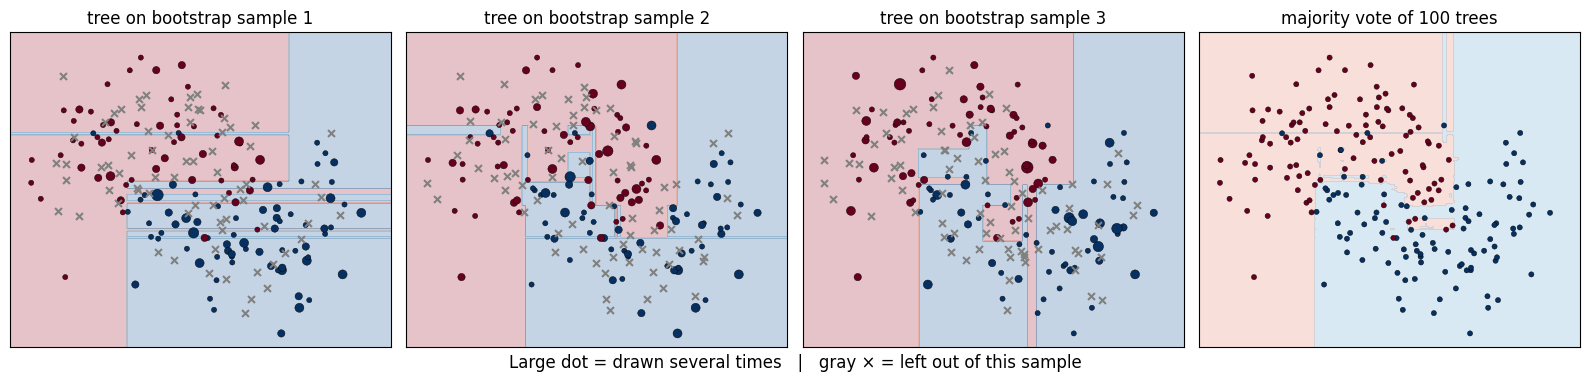

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier

rng = np.random.default_rng(1)

X, y = make_moons(n_samples=200, noise=0.30, random_state=0)
xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 300), np.linspace(-1.3, 1.8, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

trees, samples = [], []
for b in range(100):
    idx = rng.integers(0, len(X), size=len(X))
    samples.append(idx)
    trees.append(DecisionTreeClassifier(random_state=0).fit(X[idx], y[idx]))

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for b in range(3):
    counts = np.bincount(samples[b], minlength=len(X))
    used = counts > 0
    Z = trees[b].predict(grid).reshape(xx.shape)
    ax[b].contourf(xx, yy, Z, alpha=0.25, cmap="RdBu")
    ax[b].scatter(X[used, 0], X[used, 1], c=y[used], cmap="RdBu", s=14 * counts[used],
                  edgecolors="k", linewidths=0.3)
    ax[b].scatter(X[~used, 0], X[~used, 1], c="gray", marker="x", s=25)
    ax[b].set_title(f"tree on bootstrap sample {b + 1}")

vote = np.mean([t.predict(grid) for t in trees], axis=0) > 0.5
ax[3].contourf(xx, yy, vote.reshape(xx.shape), alpha=0.25, cmap="RdBu")
ax[3].scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu", s=14, edgecolors="k", linewidths=0.3)
ax[3].set_title("majority vote of 100 trees")

for a in ax:
    a.set_xticks([]); a.set_yticks([])
fig.suptitle("Large dot = drawn several times   |   gray × = left out of this sample", y=0.02)
plt.tight_layout(); plt.show()

### From bagging to **Random Forest**


Bagged trees are still quite similar to each other: if one feature is very strong, almost every
tree uses it for its first split, so the trees make correlated mistakes, and averaging correlated
predictions removes less variance than averaging different ones.

**Random Forest** adds one extra
trick on top of bagging: at every split, a tree may choose only from a **random subset of features**
(typically $\sqrt{p}$ for classification). This forces the trees to differ, so their errors cancel
better when averaged. Each individual tree becomes slightly weaker, but the ensemble is usually
better overall. Bagging is the special case where every feature is allowed at every split.

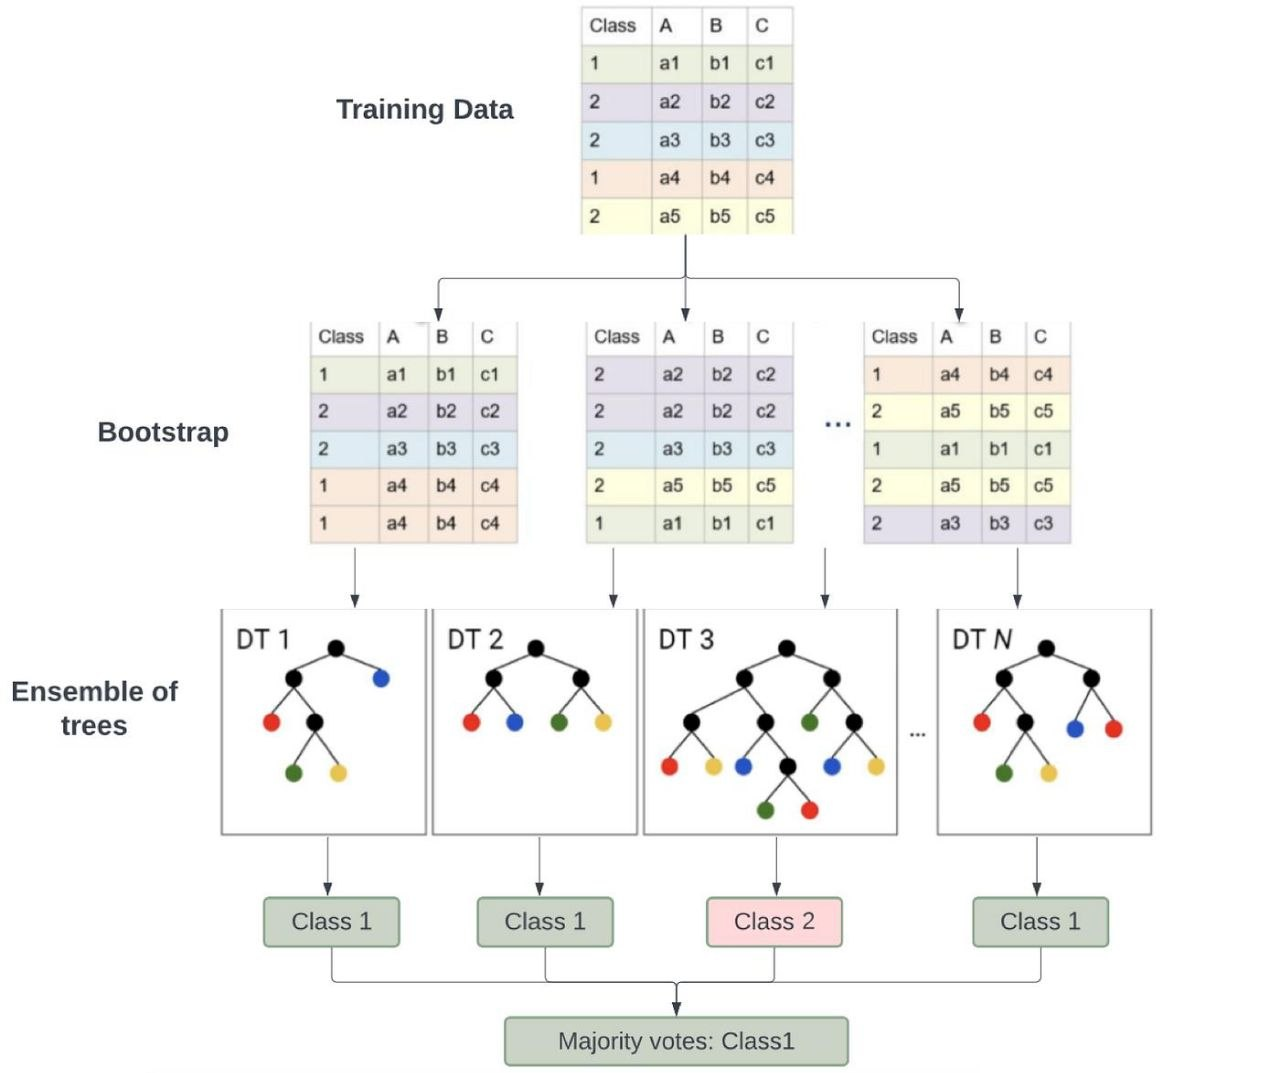

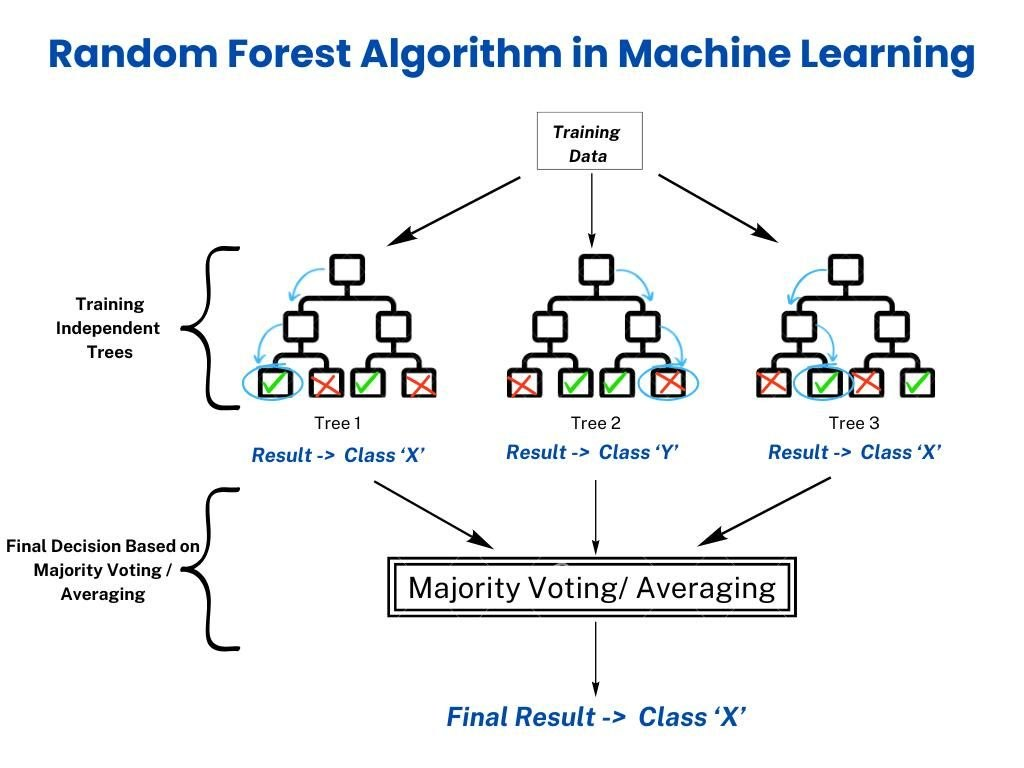

[StatQuest on Random Forest](https://www.youtube.com/watch?v=J4Wdy0Wc_xQ)


### Predicting with a Random Forest
To classify a new point $x$, we pass it through **every** tree in the forest. Each tree follows its
own sequence of splits down to a leaf and returns a class. The forest then combines these answers
by **majority vote** (for regression: by averaging):

$$\hat y(x) = \text{mode}\{\hat f^{(1)}(x), \dots, \hat f^{(B)}(x)\}$$

No bootstrapping or random feature selection happens at prediction time: both are used only while
*building* the trees. In practice, scikit-learn averages the trees' predicted class probabilities
and picks the class with the highest average, which usually agrees with the plain vote but also
takes the trees' confidence into account.

### Evaluating a Random Forest with out-of-bag (OOB) points
Each tree is trained on a bootstrap sample that leaves out about 37% of the training points.
These left-out points are the tree's **out-of-bag (OOB)** points, and the tree has never seen them.
To evaluate the forest, take every training point $x_i$ and let only the trees that did **not**
have $x_i$ in their bootstrap sample vote on it (roughly $B/e \approx 37\%$ of all trees). This gives
one *out-of-bag prediction* $\hat y_{\text{OOB}}(x_i)$ per training point. The **OOB accuracy** is
the fraction of points whose OOB prediction matches the true label:

$$\text{OOB accuracy} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\hat y_{\text{OOB}}(x_i) = y_i\right]$$

Because each point is predicted only by trees that never saw it, this behaves like a test-set
estimate, but it comes for free during training, with no separate validation set and no extra
refitting as in cross-validation. Two caveats: each point is voted on by only about a third of the
trees, so the estimate is slightly pessimistic, and $B$ must be large enough that every point has
some OOB votes. In scikit-learn, set `oob_score=True` and read `oob_score_` after fitting.

## Adaboost (Adaptive Boosting)

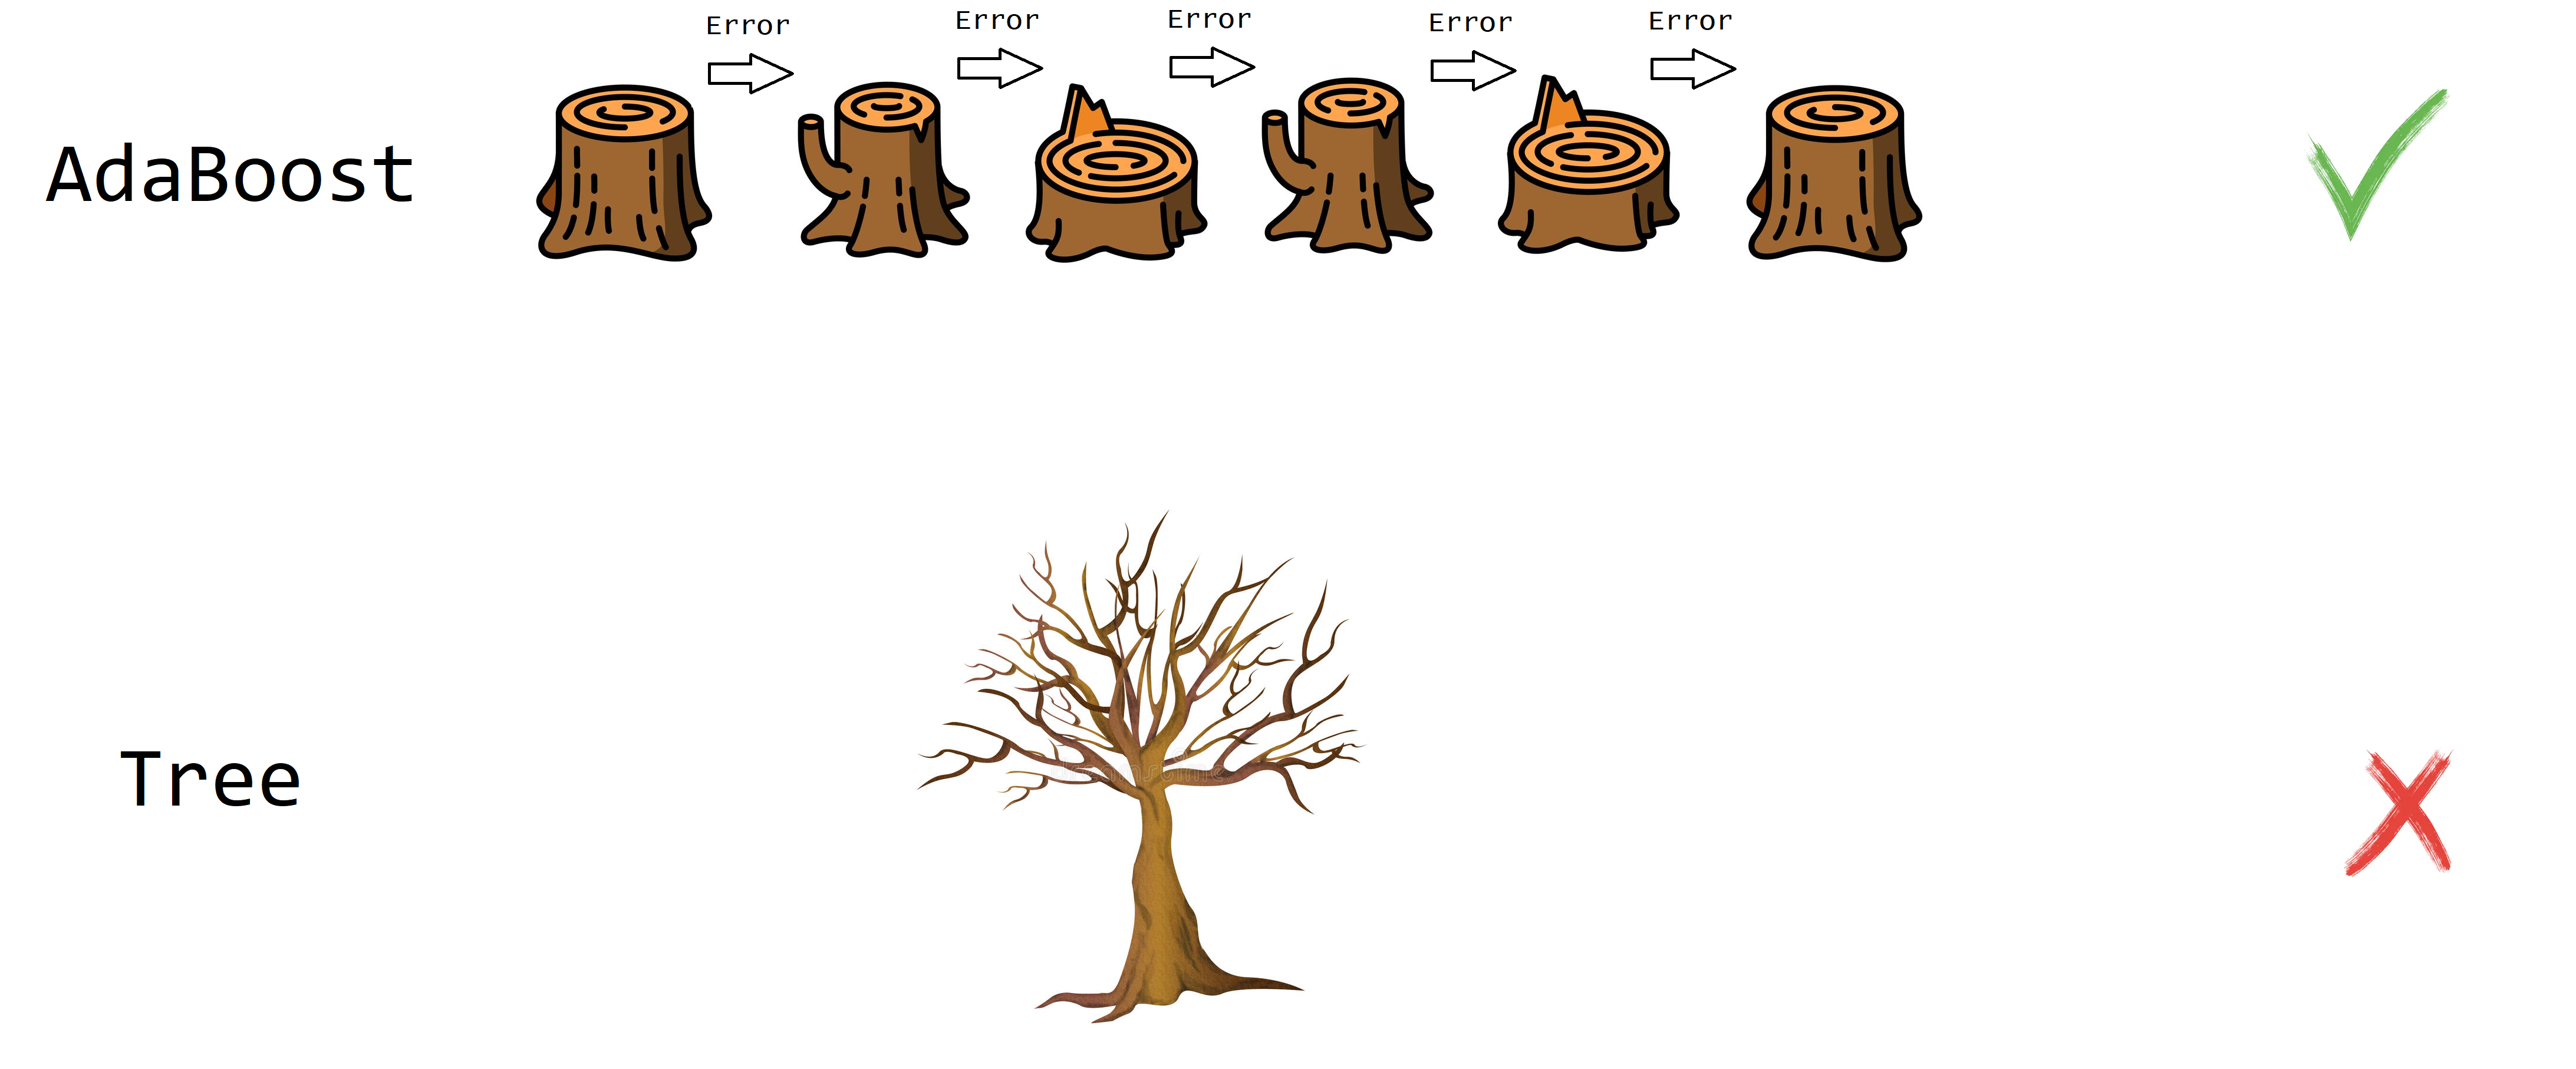

**AdaBoost** (Adaptive Boosting), introduced by Freund and Schapire (1997), is an ensemble learning algorithm that constructs a strong classifier as a weighted linear combination of weak learners. A weak learner is any model whose performance is only marginally better than random guessing, such as a decision stump.


#### Decision Stump

A **decision stump** is a decision tree of depth one, i.e., a model that performs a single split on a single feature. Given a feature index $j$ and a threshold $\theta$, it assigns a class label according to

$$h(x) = \begin{cases} +1, & \text{if } x_j > \theta, \\ -1, & \text{otherwise.} \end{cases}$$

Training a stump consists of exhaustively searching over all features and candidate thresholds, and selecting the split that minimizes the weighted classification error (or an impurity criterion such as Gini index or entropy) under the current distribution of sample weights.

Decision stumps are the canonical choice of weak learner in AdaBoost for several reasons:

- **Weak performance.** Their accuracy is only slightly better than random guessing, which satisfies the weak learning assumption required by boosting theory.
- **High bias, low variance.** A stump is too simple to overfit; boosting reduces the overall bias by combining many such models.
- **Computational efficiency and interpretability.** Training is fast, and each stump is a single human-readable rule.

In `scikit-learn`, a stump is obtained as follows:

```python
from sklearn.tree import DecisionTreeClassifier

stump = DecisionTreeClassifier(max_depth=1)
```

This is also the default base estimator of `AdaBoostClassifier`.

#### Sequential Dependence of Weak Learners

Unlike bagging-based ensembles such as random forests, where base learners are trained independently, the stumps in AdaBoost are trained **sequentially**, and the order of training is essential.

Every learner $h_t$ is defined conditionally on $h_1, \dots, h_{t-1}$, so the ensemble cannot be treated as an unordered collection of independent models, and its training cannot be parallelized across rounds.

1.   **Adaboost** combines a lot of "weak learners" to make classifications. The weak learners are almost always **stumps**.
2.   Some **stumps** get more say in classification than others.
3.   Each **stump** is made by taking the previous **stump's** mistakes into account.

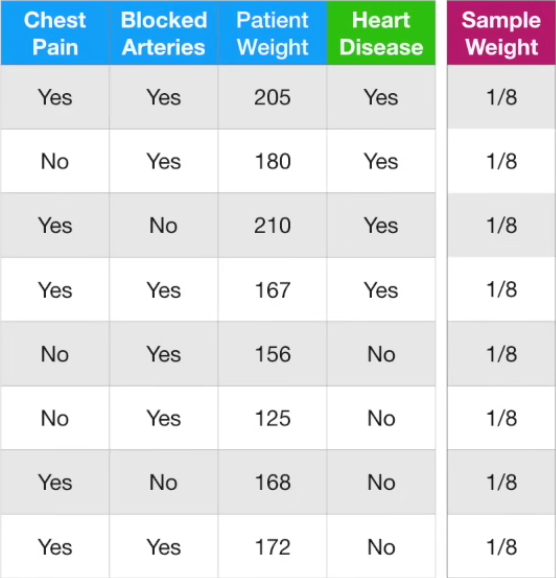

In **AdaBoost**, sample weights determine the importance of each training example during model training. Initially, all samples receive equal weights.


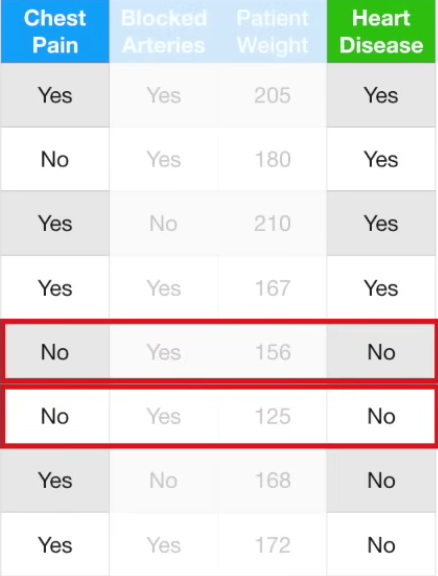

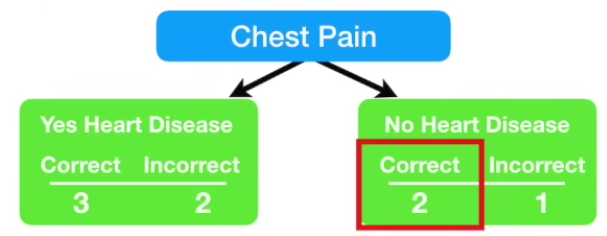

We perform the same steps as we did with **Decision Tress** classifier:
1. We evaluate each **stump**, then
2. We calculate **Gini** index to select that stump, which has the lowest value.

After the calculation of Gini index for all **stumps**, we obtain:

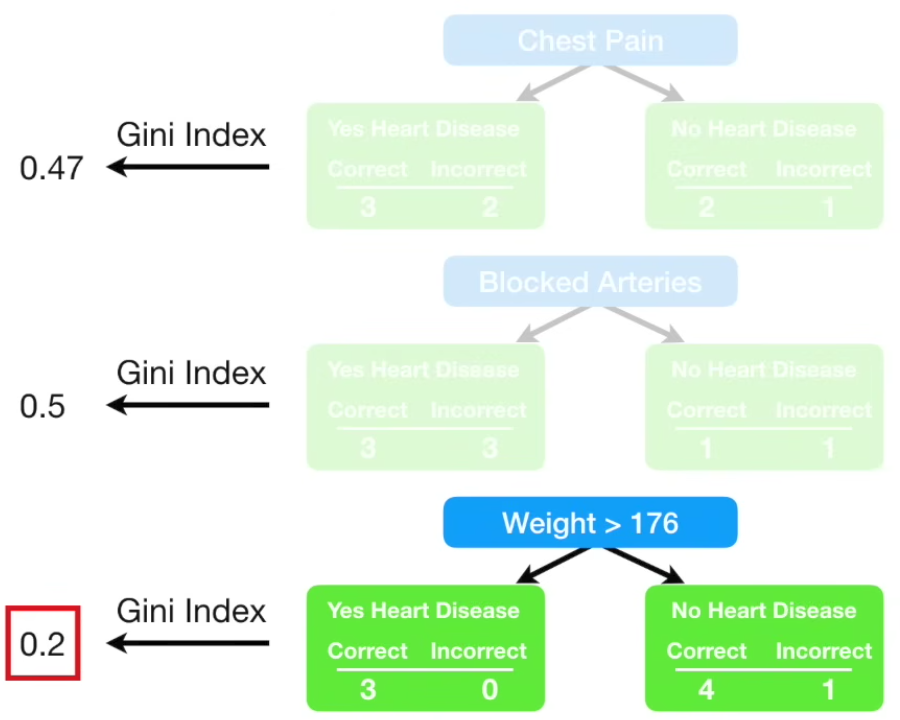

Now, we need to determine: how much is the influence of the last **stump** in the final classification. **I.e., how well it classifies samples!**

The last **stump** made one error. The **Total Error** for a stump is sum of weights associated with with *incorrectly* classified samples.

For each **stump** we can derive its **influence** or **weight** as follows:

$$
Influence = \frac{1}{2}log(\frac{1-Total Error}{Total Error})
$$

The **Influence** or **weight** of the last **stump** is


$$
Influence = \frac{1}{2}log(7) = 0.97,
$$

because its **Total Error** is $\frac{1}{8}$.

Now, we need to modify the weights so that the next **stump** will take the errors that the current **stump** made into account.

What we need is to tell the next **stump** to correctly classify sample, **which was incorrectly classified by the previous stump**, by increasing the sample weight and decreasing all the other sample weights!

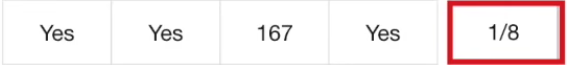

$$
w_i → w_i \exp^{Influence} = \frac{1}{8}\exp^{0.97}=0.33
$$

Now, we need to decrease other sample weights:

$$
w_i → w_i \exp^{-Influence} = \frac{1}{8}\exp^{-0.97}=0.05
$$

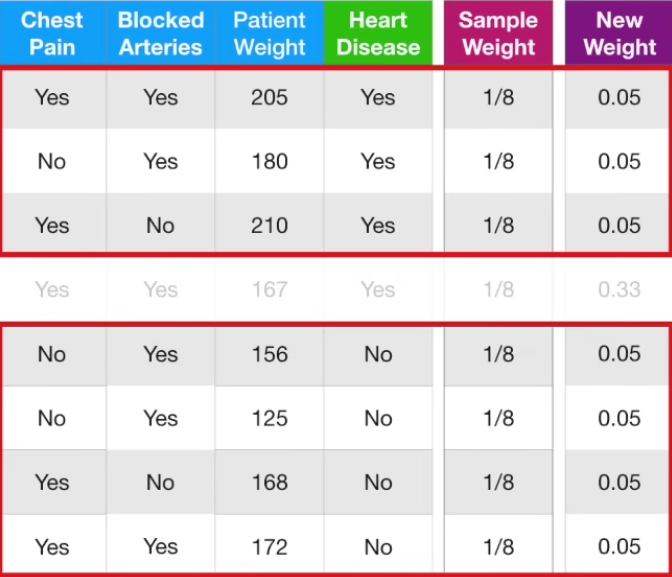

Now, we need to normalize sample weights, so that they will add up to 1.

I.e., we divide each sample weight by **0.68** (sum of all new weights):

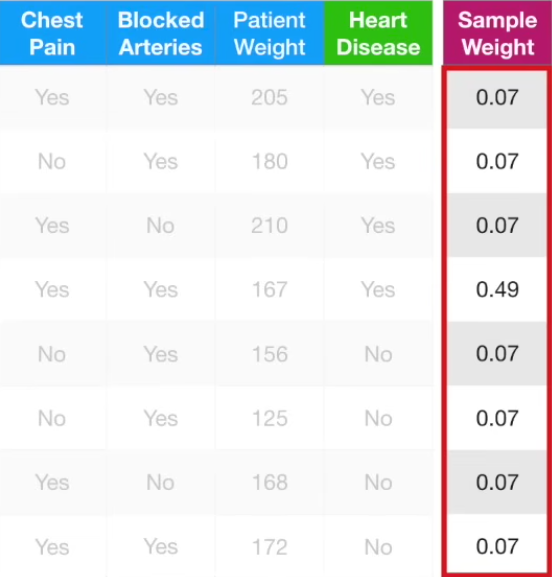

These new weights are used in the next step of building the foregoing stumps.

## AdaBoost Algorithm: Pseudocode and Explanation

### 1. Input and Output

**Input:**
- Training dataset: $$D = \{(x_i, y_i)\}_{i=1}^{N}$$
- Class labels: $$y_i \in \{-1,+1\}$$
- Number of boosting iterations: $$T$$

**Output:**
- An ensemble of weak classifiers.
- Final classifier: $$H(x)$$

### 2. Algorithm Pseudocode

#### Step 1. Initialize Sample Weights

Assign equal weights to all training samples:

$$
w_i^{(1)} = \frac{1}{N}, \qquad i=1,\ldots,N
$$

Initially, every training sample has equal importance, and the sum of all sample weights is equal to 1.

#### Step 2. Train Weak Classifiers

For each iteration:

$$
t=1,\ldots,T
$$

##### Step 2.1. Train a Weak Classifier

Train a weak classifier using the current sample weights:

$$
h_t(x)\in\{-1,+1\}
$$

The classifier predicts one of two possible classes. Samples with higher weights have a greater influence on the learning process.

##### Step 2.2. Calculate the Weighted Classification Error

$$
\varepsilon_t =
\sum_{i=1}^{N} w_i^{(t)}
\mathbb{1}\left[h_t(x_i)\neq y_i\right]
$$

The weighted error measures the classifier's performance while accounting for the importance of each sample. Misclassified samples contribute their current weights to the total error.

##### Step 2.3. Check the Classification Error

If:

$$
\varepsilon_t \geq 0.5
$$

stop training or discard the current classifier.

If:

$$
\varepsilon_t = 0
$$

the classifier correctly classifies all training samples. The algorithm may stop early because the standard classifier-weight formula is undefined at zero error.

A classifier with an error below 0.5 is better than random guessing in the binary classification setting.

##### Step 2.4. Calculate the Classifier Weight

For a valid error:

$$
0 < \varepsilon_t < 0.5
$$

calculate the classifier's contribution to the ensemble:

$$
\alpha_t =
\frac{1}{2}
\ln\left(\frac{1-\varepsilon_t}{\varepsilon_t}\right)
$$

A smaller classification error results in a larger value of the classifier weight. Therefore, more accurate classifiers have a greater influence on the final prediction.

##### Step 2.5. Update Sample Weights

Update the weights of all training samples:

$$
\widetilde{w}_i^{(t+1)} =
w_i^{(t)}
\exp\left(-\alpha_t y_i h_t(x_i)\right)
$$

For correctly classified samples:

$$
y_i h_t(x_i)=+1
$$

Their weights decrease.

For misclassified samples:

$$
y_i h_t(x_i)=-1
$$

Their weights increase.

This step makes difficult samples more important during subsequent iterations.

##### Step 2.6. Normalize Sample Weights

Normalize the updated weights:

$$
w_i^{(t+1)} =
\frac{\widetilde{w}_i^{(t+1)}}
{\sum_{j=1}^{N}\widetilde{w}_j^{(t+1)}}
$$

After normalization:

$$
\sum_{i=1}^{N}w_i^{(t+1)}=1
$$

This ensures that the sample weights form a normalized distribution for the next iteration.

#### Step 3. Construct the Final Ensemble

Combine all accepted weak classifiers using their respective weights:

$$
H(x)=\sum_{t=1}^{M}\alpha_t h_t(x)
$$

Here, $$M\leq T$$ is the number of weak classifiers accepted during training.

The final predicted class is determined by the sign of the weighted sum:

$$
\hat{y}=\operatorname{sign}(H(x))
$$

The prediction rule is:

$$
\hat{y} =
\begin{cases}
+1, & H(x)>0,\\
-1, & H(x)<0.
\end{cases}
$$

If the weighted sum equals zero, a predefined tie-breaking rule is applied.

### 3. Result and Interpretation

AdaBoost (Adaptive Boosting) is an ensemble learning algorithm that combines multiple weak classifiers to create a stronger classifier.

The algorithm trains weak classifiers sequentially. After each iteration, it increases the relative importance of misclassified samples and decreases the relative importance of correctly classified samples.

Each weak classifier receives a weight based on its classification error. More accurate classifiers contribute more strongly to the final prediction.

**Key idea:** AdaBoost improves classification by focusing successive learning iterations on samples that previous classifiers found difficult to classify.


### A. Weak Learners Do Not Have to Be Decision Stumps

A decision stump is a decision tree with a maximum depth of one. It typically contains one root node and two leaf nodes.

However, AdaBoost does not require every weak learner to be a decision stump. It can use more complex decision trees or other classification algorithms, provided that the chosen estimator supports sample weights and satisfies the requirements of the AdaBoost implementation.

For example, consider the following configurations:

- `max_depth=1`: a decision stump with at most two leaf nodes.
- `max_depth=2`: a decision tree with at most four leaf nodes.
- `max_depth=3`: a decision tree with at most eight leaf nodes.

These are maximum numbers of leaves for binary decision trees; the actual number may be smaller.

To use deeper trees in AdaBoost, we only need to change the base estimator:

```python
weak_learner = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)
```

The training process remains conceptually the same: AdaBoost trains weak learners sequentially, assigns more importance to incorrectly classified observations through sample-weight updates, and combines the learners into a final ensemble.

**Important:** Deeper trees are more expressive, but they may also overfit and reduce the diversity or effectiveness of the ensemble. The appropriate tree depth should be selected using validation or cross-validation.


In [ ]:
import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# 2. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Define a weak learner
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# 4. Create the AdaBoost ensemble
model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

# 5. Train the model
model.fit(X_train, y_train)

# 6. Make predictions
y_pred = model.predict(X_test)

# 7. Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# 8. Inspect the individual weak learners
print("Number of estimators:", len(model.estimators_))

for t, tree in enumerate(model.estimators_[:5], start=1):
    print(
        f"Estimator {t}: "
        f"depth={tree.get_depth()}, "
        f"leaves={tree.get_n_leaves()}, "
        f"weight={model.estimator_weights_[t-1]:.4f}"
    )

Accuracy: 0.9333333333333333

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Number of estimators: 50
Estimator 1: depth=1, leaves=2, weight=1.3863
Estimator 2: depth=1, leaves=2, weight=2.1871
Estimator 3: depth=1, leaves=2, weight=2.8511
Estimator 4: depth=1, leaves=2, weight=1.8189
Estimator 5: depth=1, leaves=2, weight=2.5080


### B. Multiclass Classification with AdaBoost

The original AdaBoost algorithm is commonly introduced as a binary classification algorithm, where class labels are represented as

$$
y_i \in \{-1,+1\}.
$$

However, AdaBoost can also be extended to multiclass classification, where each observation belongs to one of $K$ classes.

One popular extension is **SAMME (Stagewise Additive Modeling using a Multi-class Exponential loss function)**.

Unlike binary AdaBoost, multiclass SAMME uses the following classifier weight:

$$
\alpha_t =
\ln\left(\frac{1-\varepsilon_t}{\varepsilon_t}\right)
+
\ln(K-1),
$$

where:

- $\varepsilon_t$ is the weighted classification error of the current weak learner.
- $K$ is the number of classes.
- $\alpha_t$ determines the contribution of the weak learner to the ensemble.

For SAMME, a weak learner must perform better than random guessing in the weighted multiclass setting:

$$
\varepsilon_t < 1-\frac{1}{K}.
$$

For example:

- Binary classification ($K=2$): $\varepsilon_t < 0.5$.
- Three-class classification ($K=3$): $\varepsilon_t < 2/3$.
- Four-class classification ($K=4$): $\varepsilon_t < 3/4$.

The sample weights are updated according to

$$
\widetilde{w}_i^{(t+1)}
=
w_i^{(t)}
\exp\left(
\alpha_t \mathbb{1}[h_t(x_i)\neq y_i]
\right).
$$

Misclassified observations receive increased weights, while correctly classified observations retain their weights before normalization.

The final prediction is obtained by combining the weighted predictions of all weak learners and selecting the class with the highest total vote.

In scikit-learn, `AdaBoostClassifier` supports multiclass classification. The following example uses the SAMME algorithm with decision trees as weak learners:

```python
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
```

No manual conversion of class labels to $-1$ and $+1$ is needed. The classifier handles the multiclass labels directly.

**Key idea:** Multiclass AdaBoost preserves the sequential boosting strategy but uses a classifier-weight formula and prediction rule adapted to multiple classes.
